<div align="center">

![Logo UP](https://www.palermo.edu/images/header/logo.png)

####
#### Universidad de Palermo - Ingeniería en Informática
#### Trabajo Final de Grado
<br>

**Diseño y prueba de concepto de un modelo predictivo de brotes de dengue en la Ciudad Autónoma de Buenos Aires**
<br><br>
</div>
<div align="left">
Realizado por: Carlos Lazzarino <br>
</div>

Este documento presenta el *pipeline* para el diseño, entrenamiento y evaluación de modelos predictivos de *Machine Learning* aplicados a la anticipación temporal de casos de dengue en la Ciudad Autónoma de Buenos Aires (CABA).

**Contenido:**
1. Configuración de entorno y carga de librerías.
2. Carga de datos
3. Partición por temporada, preprocesamiento y limpieza
4. Feature Engineering (Lags, Tendencias y Medias Móviles).
5. Entrenamiento y optimización de hiperparámetros (*LightGBM*, *SVR* y *Redes Neuronales* con Torch).
6. Predicción sobre el set de prueba (temporada 2023/24).
7. Metricas de error

## 1. Configuración de Entorno y Carga de Librerías

En caso de correrlo en Google Colab, es necesario:
*   Asegurar que el entorno de ejecución esté configurado en **R**.
*   Para el entrenamiento, puede modificarse la configuración a "Acelerador de hardware" a GPU (T4 o similar) en las opciones del entorno de ejecución.
*   Cargar el archivo .csv en el directorio input.

In [1]:
# Instalación y carga de paquetes

packages <- c("data.table", "tidyverse", "lightgbm", "zoo", "rBayesianOptimization", "e1071", "MMWRweek")
packages_faltantes <- packages[!(packages %in% installed.packages()[,"Package"])]

if(length(packages_faltantes) > 0) {
  cat("Instalando paquetes faltantes:", paste(packages_faltantes, collapse=", "), "\n")
  install.packages(packages_faltantes, quiet = TRUE)
} else {
  cat("Todos los paquetes ya están instalados.\n")
}

# Cargamos todas las librerías
invisible(lapply(packages, function(p) suppressPackageStartupMessages(library(p, character.only = TRUE))))
cat("Paquetes cargados correctamente.\n")

Todos los paquetes ya están instalados.
Paquetes cargados correctamente.


In [2]:
# Instalación y carga de Torch para R (para las redes Neuronales)

if (!("torch" %in% installed.packages()[,"Package"])) {
  cat("Instalando el paquete base 'torch'...\n")
  install.packages("torch", quiet = TRUE)
}
suppressPackageStartupMessages(library(torch))

if (!torch_is_installed()) {
  cat("Descargando C++ libtorch (esto se hace una sola vez por sesión pero pesa ~1.5GB, puede demorar 15-20 minutos)...\n")
  install_torch()
}

if (!("luz" %in% installed.packages()[,"Package"])) {
  cat("Instalando 'luz' (wrapper para Torch)...\n")
  install.packages("luz", quiet = TRUE)
}
suppressPackageStartupMessages(library(luz))

cat("Torch cargado correctamente.\n")

Torch cargado correctamente.


## 2. Carga de Datos

Los datos provienen de la integración de fuentes públicas (BADATA, Ministerio de Salud y Open-Meteo). El dataset maestro unificado consolida la serie temporal histórica agrupada por semana epidemiológica (SE), incluyendo los casos confirmados que fueron notificados y las métricas ambientales de CABA.

In [3]:
# 2. Carga del Dataset Consolidado

# Modificar Data_Path en caso de ser necesario
DATA_PATH_INPUT <- "./input/"
DATA_PATH_OUTPUT <- "./output/"

# Archivo consolidado
archivo_dataset <- paste0(DATA_PATH_INPUT, "DATASET_DENGUE.csv")

if (file.exists(archivo_dataset)) {
  cat("Cargando el dataset...\n")
  dataset <- fread(archivo_dataset)
} else {
  stop(paste("ERROR: No se encontró el archivo en:", archivo_dataset, "\nAsegúrese de subir 'DATASET_DENGUE.csv' a la carpeta input."))
}

cat("\nDataset cargado con éxito.\n")
cat("Filas totales:", nrow(dataset), "\n")
cat("Columnas conservadas:", ncol(dataset), "\n")
cat("Años abarcados:", min(dataset$ano, na.rm = TRUE), "-", max(dataset$ano, na.rm = TRUE), "\n")

Cargando el dataset...

Dataset cargado con éxito.
Filas totales: 7005 
Columnas conservadas: 18 
Años abarcados: 2016 - 2024 


## 3. Partición de Datos y Preprocesamiento
Se consolidan los datos de las distintas comunas en una única serie temporal para toda la Ciudad de Buenos Aires (CABA).

El *pipeline* analítico consiste de:
1. **Partición de Datos**: Se convierten las variables numéricas. Cada semana epidemiológica (SE) se fecha por su día de inicio y se asigna a una temporada que va del 1/8 al 31/7 del año siguiente. Se separa cronológicamente la temporada 2023-2024 (que va entre el 1/8/23 al 31/7/24) de la serie temporal para el set de prueba (*Test*) y lo restante para entrenamiento. Se descartan semanas posteriores al 31/7/24.
2. **Consolidación e Imputación:** Agrupación e imputación direccional (`LOCF`) para rellenar datos ambientales faltantes.
3. **Análisis Exploratorio del Dataset de Entrenamiento**.


In [4]:
# 3.1 Conversión numérica y consolidación de comunas en una serie semanal para CABA
cols_climaticas <- c("temp_media_semanal", "temp_min_semanal", "temp_max_semanal",
                     "lluvia_semanal", "viento_semanal")
cols_a_numericas <- c("casos_totales", cols_climaticas)
dataset[, (cols_a_numericas) := lapply(.SD, function(x) as.numeric(gsub(",", ".", as.character(x)))),
        .SDcols = cols_a_numericas]

dataset_caba <- dataset[, c(list(casos_totales = sum(casos_totales, na.rm = TRUE)),
                            lapply(.SD, mean, na.rm = TRUE)),
                        by = .(ano, semana_epidemiologica), .SDcols = cols_climaticas]
for (col in cols_climaticas) set(dataset_caba, which(is.nan(dataset_caba[[col]])), col, NA_real_)

# Fecha de inicio de la SE y temporada (1/8 al 31/7)
dataset_caba[, fecha_se := MMWRweek2Date(MMWRyear = ano, MMWRweek = semana_epidemiologica)]
dataset_caba[, temporada_inicio := ifelse(month(fecha_se) >= 8, year(fecha_se), year(fecha_se) - 1L)]
dataset_caba[, temporada := paste0(temporada_inicio, "/", substr(temporada_inicio + 1, 3, 4))]
setorder(dataset_caba, fecha_se)
if (any(diff(dataset_caba$fecha_se) != 7)) warning("Hay semanas faltantes en la serie")

# Control: casos por año calendario (permite verificar desde cuándo hay datos de casos)
print(dataset_caba[, .(casos = sum(casos_totales)), by = ano])


     ano casos
   <int> <num>
1:  2016     0
2:  2017     0
3:  2018    60
4:  2019    66
5:  2020  7679
6:  2021     8
7:  2022    18
8:  2023 20941
9:  2024 43902


In [5]:
# 3.2 Partición: test = temporada 2023/24 (1/8/2023 al 31/7/2024)
fecha_ini_test  <- as.Date("2023-08-01")
fecha_fin_test  <- as.Date("2024-07-31")
fecha_ini_casos <- as.Date("2020-01-01")   # primer período con casos registrados en el dataset

train_data_raw <- dataset_caba[fecha_se <  fecha_ini_test]
test_data_raw  <- dataset_caba[fecha_se >= fecha_ini_test & fecha_se <= fecha_fin_test]
# Las semanas posteriores al 31/7/2024 se descartan: son futuras respecto del test.

cat("Train:", nrow(train_data_raw), "semanas |", format(min(train_data_raw$fecha_se)), "a", format(max(train_data_raw$fecha_se)), "\n")
cat("  de las cuales con datos de casos (desde", format(fecha_ini_casos), "):",
    nrow(train_data_raw[fecha_se >= fecha_ini_casos]), "\n")
cat("Test :", nrow(test_data_raw),  "semanas |", format(min(test_data_raw$fecha_se)),  "a", format(max(test_data_raw$fecha_se)), "\n")
cat("Semanas descartadas posteriores al test:", nrow(dataset_caba[fecha_se > fecha_fin_test]), "\n")

Train: 394 semanas | 2016-01-17 a 2023-07-30 
  de las cuales con datos de casos (desde 2020-01-01 ): 187 
Test : 52 semanas | 2023-08-06 a 2024-07-28 
Semanas descartadas posteriores al test: 21 


In [6]:
# 3.3 Conteo de NAs y Resumen de la Variable Objetivo (casos_totales)

# 1. NAs en Train (incluye la historia climática previa a 2020)
nas_por_columna <- sapply(train_data_raw, function(x) sum(is.na(x)))
if(sum(nas_por_columna) > 0) {
  print(nas_por_columna[nas_por_columna > 0])
} else {
  cat("No se detectaron valores nulos en las mediciones de Train.\n")
}
cat("Total de NAs en Train:", sum(nas_por_columna), "\n\n")

# 2. Resumen de casos_totales en el período con datos de casos
cat("Resumen de la variable objetivo (casos_totales) en Train desde", format(fecha_ini_casos), ":\n")
print(summary(train_data_raw[fecha_se >= fecha_ini_casos, casos_totales]))

No se detectaron valores nulos en las mediciones de Train.
Total de NAs en Train: 0 

Resumen de la variable objetivo (casos_totales) en Train desde 2020-01-01 :
   Min. 1st Qu.  Median    Mean 3rd Qu.    Max. 
    0.0     0.0     0.0   152.5     5.0  3931.0 


   temporada semanas casos_temporada pico_semanal casos_ago_dic casos_diciembre
      <char>   <int>           <num>        <num>         <num>           <num>
1:   2019/20      30            7677         1152             0               0
2:   2020/21      52               8            2             0               0
3:   2021/22      53              14            2             0               0
4:   2022/23      52           20827         3931             4               0


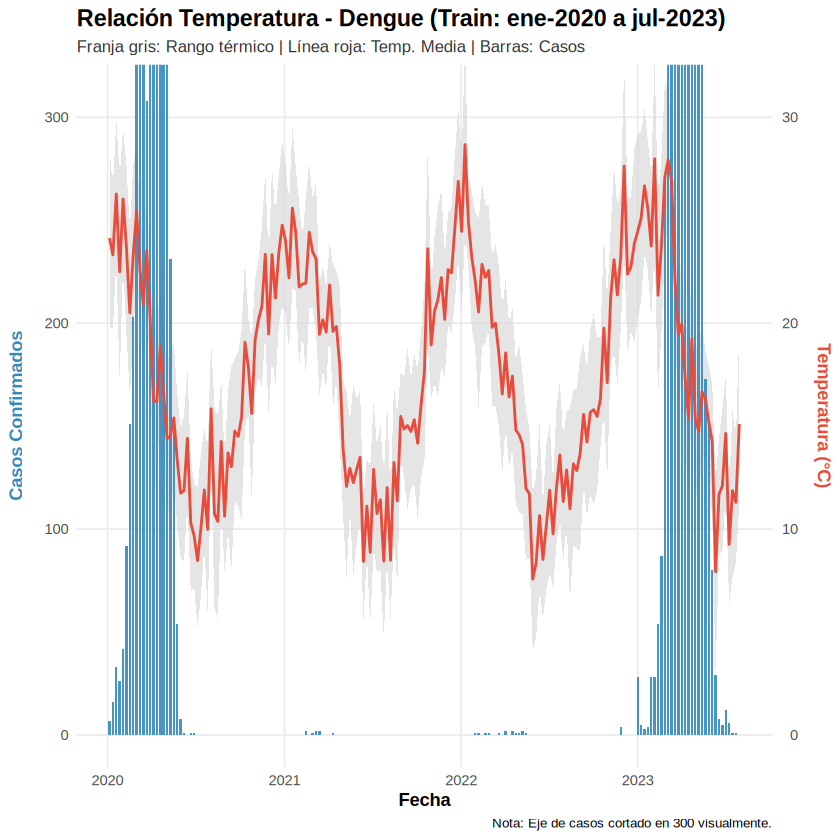

In [7]:
# 3.4 Análisis Exploratorio del Set de Entrenamiento (EDA), período con datos de casos
df_plot <- train_data_raw[fecha_se >= fecha_ini_casos]

# Para la visualización en el gráfico 300 casos equivalen a 30 grados (coeficiente 10)
coeff <- 10

eda_plot <- ggplot(df_plot, aes(x = fecha_se)) +
  geom_ribbon(aes(ymin = temp_min_semanal * coeff, ymax = temp_max_semanal * coeff),
              fill = "gray85", alpha = 0.7) +
  geom_col(aes(y = casos_totales), fill = "#348ABD", alpha = 0.9, width = 5) +
  geom_line(aes(y = temp_media_semanal * coeff), color = "#E74C3C", linewidth = 0.8) +
  scale_y_continuous(
    name = "Casos Confirmados",
    breaks = seq(0, 300, 100),
    sec.axis = sec_axis(~./coeff, name = "Temperatura (°C)", breaks = seq(0, 30, 10))
  ) +
  coord_cartesian(ylim = c(0, 310)) +
  labs(
    title = "Relación Temperatura - Dengue (Train: ene-2020 a jul-2023)",
    subtitle = "Franja gris: Rango térmico | Línea roja: Temp. Media | Barras: Casos",
    x = "Fecha",
    caption = "Nota: Eje de casos cortado en 300 visualmente."
  ) +
  theme_minimal() +
  theme(
    plot.title = element_text(face = "bold", size = 14),
    plot.subtitle = element_text(size = 10, color = "gray20"),
    axis.title.y = element_text(color = "#348ABD", face = "bold", margin = margin(r = 10)),
    axis.title.y.right = element_text(color = "#E74C3C", face = "bold", margin = margin(l = 10)),
    axis.title.x = element_text(face = "bold"),
    plot.caption = element_text(hjust = 1, size = 8, color = "black"),
    panel.grid.minor = element_blank()
  )

print(eda_plot)

# Resumen por temporada (solo semanas con datos de casos)
resumen_temporadas <- df_plot[, .(
  semanas         = .N,
  casos_temporada = sum(casos_totales),
  pico_semanal    = max(casos_totales),
  casos_ago_dic   = sum(casos_totales[month(fecha_se) %in% 8:12]),
  casos_diciembre = sum(casos_totales[month(fecha_se) == 12])
), by = temporada]
print(resumen_temporadas)

## 4. Feature Engineering y Normalización

El horizonte de anticipación es de **2 semanas** (H = 2): para predecir los casos de la semana *t* solo se utiliza información disponible hasta *t-2*. Por eso el clima de la semana *t* no se incluye como variable.

Variables construidas:
* **Variable objetivo en escala logarítmica** (`log1p(casos)`), para atenuar el peso de los picos y de las semanas sin casos. Las predicciones se vuelven a cantidad de casos con `expm1`.
* **Lags** de casos y clima en *t-2*, *t-3* y *t-4*.
* **Tendencia de casos:** crecimiento entre *t-2* y *t-3*, y entre *t-2* y *t-4*.
* **Medias móviles** de casos (4 semanas) y clima (4 y 8 semanas), cerradas en *t-2*; lluvia acumulada y temperatura media de 12 semanas.
* **Casos acumulados de la temporada** hasta *t-2*, como indicador de la intensidad de la temporada.
* **Posición dentro de la temporada** (seno y coseno de la semana de temporada).
* **Persistencia** (casos en *t-2*): Linea base de comparación.

Se descartan las semanas sin historia suficiente para calcular los rezagos y las semanas previas a 2020 (sin datos de casos). Se aplica `Min-Max Scaling`: los mínimos y máximos se calculan sobre el *Train Set* y se aplican sin cambios al *Test Set*.

In [8]:
# 4.1 Definición de la función Feature Engineering (Horizonte de anticipación: 2 semanas)

engineer_features <- function(dt, cols_clima, h = 2) {
  dt <- copy(dt)
  setorder(dt, fecha_se)
  dt[, log_casos := log1p(casos_totales)]
  lag_h <- function(x) shift(x, h)

  # A. Rezagos de casos y clima: t-h, t-h-1, t-h-2
  for (l in h:(h + 2)) {
    dt[, paste0("log_casos_lag", l) := shift(log_casos, l)]
    dt[, paste0(cols_clima, "_lag", l) := shift(.SD, l), .SDcols = cols_clima]
  }
  # B. Tendencia de casos (crecimiento en escala log)
  dt[, crec_casos_1s := get(paste0("log_casos_lag", h)) - get(paste0("log_casos_lag", h + 1))]
  dt[, crec_casos_2s := get(paste0("log_casos_lag", h)) - get(paste0("log_casos_lag", h + 2))]
  # C. Medias móviles cerradas en t-h
  dt[, log_casos_rmean4 := frollmean(lag_h(log_casos), 4)]
  for (col in cols_clima) {
    dt[, paste0(col, "_rmean4") := frollmean(lag_h(get(col)), 4)]
    dt[, paste0(col, "_rmean8") := frollmean(lag_h(get(col)), 8)]
  }
  dt[, lluvia_acum12  := frollsum(lag_h(lluvia_semanal), 12)]
  dt[, temp_rmean12   := frollmean(lag_h(temp_media_semanal), 12)]
  # D. Casos acumulados de la temporada hasta t-h ("temporada agresiva")
  dt[, casos_lag_h := fifelse(is.na(lag_h(casos_totales)), 0, lag_h(casos_totales))]
  dt[, log_acum_temporada := log1p(cumsum(casos_lag_h)), by = temporada]
  # E. Posición dentro de la temporada (estacionalidad)
  dt[, semana_temp := as.integer(fecha_se - as.Date(paste0(temporada_inicio, "-08-01"))) %/% 7 + 1L]
  dt[, `:=`(sem_sin = sin(2 * pi * semana_temp / 52), sem_cos = cos(2 * pi * semana_temp / 52))]
  # F. Línea base ingenua (persistencia) sin escalar, solo para comparar
  dt[, naive_log := lag_h(log_casos)]
  dt
}

cols_no_predictoras <- c("ano", "semana_epidemiologica", "fecha_se", "temporada", "temporada_inicio",
                         "casos_totales", "log_casos", "casos_lag_h", "semana_temp", "naive_log",
                         cols_climaticas)   # el clima de la semana t no se conoce con 2 semanas de anticipación

In [9]:
# 4.2 Relleno de NAs (Imputación LOCF, solo hacia adelante) en Train
train_data_raw[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm = FALSE)), .SDcols = cols_climaticas]

# 4.3 Feature Engineering (se calcula sobre toda la serie para aprovechar la historia climática)
cat("Aplicando Feature Engineering en Train (rezagos, tendencias, medias móviles)...\n")
train_data_fe <- engineer_features(train_data_raw, cols_climaticas, h = 2)
features_model <- setdiff(names(train_data_fe), cols_no_predictoras)
# Se conservan solo semanas con datos de casos y con historia completa
train_data_fe <- train_data_fe[fecha_se >= fecha_ini_casos & complete.cases(train_data_fe[, ..features_model])]

# 4.4 Normalización Min-Max (parámetros calculados solo sobre Train)
escalado_params <- list()

for(col in features_model) {
  min_val <- min(train_data_fe[[col]], na.rm = TRUE)
  max_val <- max(train_data_fe[[col]], na.rm = TRUE)
  escalado_params[[col]] <- c(min = min_val, max = max_val)

  if(max_val - min_val > 0) {
    train_data_fe[, (col) := (get(col) - min_val) / (max_val - min_val)]
  } else {
    train_data_fe[, (col) := 0]
  }
}

train_data <- train_data_fe

cat("Normalización Min-Max en Train completa.\n")
cat("Dimensiones Train:", dim(train_data)[1], "x", dim(train_data)[2], "\n")

Aplicando Feature Engineering en Train (rezagos, tendencias, medias móviles)...
Normalización Min-Max en Train completa.
Dimensiones Train: 187 x 51 


In [10]:
# 4.5 Matrices de entrenamiento y validación temporal por temporadas
X_train <- as.matrix(train_data[, ..features_model])
y_train <- train_data$log_casos

# Validación expansiva: cada temporada (desde la segunda con datos) se predice
# con un modelo entrenado solo con las temporadas anteriores
temporadas_val <- sort(unique(train_data$temporada_inicio))
temporadas_val <- temporadas_val[temporadas_val > min(temporadas_val)]
folds_temporales <- lapply(temporadas_val, function(s) list(
  tr = which(train_data$temporada_inicio <  s),
  va = which(train_data$temporada_inicio == s)))

print(rbindlist(lapply(seq_along(folds_temporales), function(i) data.table(
  temporada_validacion = paste0(temporadas_val[i], "/", substr(temporadas_val[i] + 1, 3, 4)),
  semanas_train = length(folds_temporales[[i]]$tr),
  casos_train   = sum(train_data$casos_totales[folds_temporales[[i]]$tr]),
  casos_valid   = sum(train_data$casos_totales[folds_temporales[[i]]$va])))))

mae_casos <- function(y_log, p_log) mean(abs(expm1(y_log) - pmax(0, expm1(p_log))))

   temporada_validacion semanas_train casos_train casos_valid
                 <char>         <int>       <num>       <num>
1:              2020/21            30        7677           8
2:              2021/22            82        7685          14
3:              2022/23           135        7699       20827


## 5. Entrenamiento y Optimización de Hiperparámetros

Los tres modelos predicen `log1p(casos)` y se comparan por el **MAE expresado en cantidad de casos**, que se busca minimizar.

**Validación temporal:** cada temporada de validación se predice con un modelo entrenado únicamente con las temporadas anteriores. No se utiliza validación cruzada aleatoria porque incorporaría semanas futuras al entrenamiento.

* **LightGBM:** optimización bayesiana de hiperparámetros; la cantidad de árboles se define por *early stopping*.
* **SVR (kernel radial):** búsqueda en grilla de `cost`, `gamma` y `epsilon`.
* **Red neuronal (Torch):** perceptrón multicapa con dos capas ocultas; se comparan tres configuraciones.
* **Persistencia:** línea base que predice para *t* los casos observados en *t-2*. Un modelo es útil si su MAE es menor que el de esta referencia.

Los hiperparámetros elegidos se guardan en archivos `.rds` en `output/` para no recalcularlos en futuras ejecuciones.

In [11]:
# 5.1 Modelo 1: LightGBM (Gradient Boosting - Regresión sobre log1p(casos))
cat("\n--- Modelo 1: LightGBM ---\n")

cv_lgb_temporal <- function(pars) {
  res <- sapply(folds_temporales, function(f) {
    dtr <- lgb.Dataset(X_train[f$tr, ], label = y_train[f$tr])
    dva <- lgb.Dataset.create.valid(dtr, X_train[f$va, ], label = y_train[f$va])
    m <- lgb.train(pars, dtr, nrounds = 1000, valids = list(val = dva),
                   early_stopping_rounds = 50, verbose = -1)
    c(mae = mae_casos(y_train[f$va], predict(m, X_train[f$va, ])), iter = m$best_iter)
  })
  list(mae = mean(res["mae", ]), iter = round(median(res["iter", ])))
}

base_lgb <- list(objective = "regression", metric = "l1", bagging_fraction = 0.8, bagging_freq = 5,
                 seed = 42, deterministic = TRUE, num_threads = 1, verbosity = -1)

archivo_params_lgb <- paste0(DATA_PATH_OUTPUT, "params_lgb.rds")
if (file.exists(archivo_params_lgb)) {
  cat("Cargando hiperparámetros guardados...\n")
  mejor_lgb <- readRDS(archivo_params_lgb)
} else {
  cat("Iniciando Optimización Bayesiana (minimizando MAE en casos)...\n")
  lgb_eval_fun <- function(learning_rate, num_leaves, min_data_in_leaf, feature_fraction, lambda_l2) {
    pars <- c(base_lgb, list(learning_rate = learning_rate, num_leaves = as.integer(num_leaves),
                             min_data_in_leaf = as.integer(min_data_in_leaf),
                             feature_fraction = feature_fraction, lambda_l2 = lambda_l2))
    list(Score = -cv_lgb_temporal(pars)$mae, Pred = 0)
  }
  set.seed(42)
  opt_res <- BayesianOptimization(lgb_eval_fun,
    bounds = list(learning_rate = c(0.01, 0.1), num_leaves = c(4L, 31L), min_data_in_leaf = c(3L, 30L),
                  feature_fraction = c(0.5, 1.0), lambda_l2 = c(0, 10)),
    init_points = 8, n_iter = 20, acq = "ucb")
  bp <- as.list(opt_res$Best_Par)
  bp$num_leaves <- as.integer(bp$num_leaves); bp$min_data_in_leaf <- as.integer(bp$min_data_in_leaf)
  pars <- c(base_lgb, bp)
  res_cv <- cv_lgb_temporal(pars)
  mejor_lgb <- list(params = pars, nrounds = res_cv$iter, mae_cv = res_cv$mae)
  dir.create(DATA_PATH_OUTPUT, showWarnings = FALSE)
  saveRDS(mejor_lgb, archivo_params_lgb)
}
modelo_lgb <- lgb.train(mejor_lgb$params, lgb.Dataset(X_train, label = y_train), nrounds = mejor_lgb$nrounds)
cat("LightGBM entrenado. MAE de validación temporal:", round(mejor_lgb$mae_cv, 1), "casos\n")


--- Modelo 1: LightGBM ---
Iniciando Optimización Bayesiana (minimizando MAE en casos)...
elapsed = 0.193	Round = 1	learning_rate = 0.09233254	num_leaves = 22.0000	min_data_in_leaf = 29.0000	feature_fraction = 0.5412188	lambda_l2 = 3.881083	Value = -139.3438 
elapsed = 0.193	Round = 2	learning_rate = 0.09433679	num_leaves = 23.0000	min_data_in_leaf = 6.0000	feature_fraction = 0.7571059	lambda_l2 = 6.851697	Value = -113.4188 
elapsed = 0.143	Round = 3	learning_rate = 0.03575256	num_leaves = 16.0000	min_data_in_leaf = 16.0000	feature_fraction = 0.6951017	lambda_l2 = 0.03948339	Value = -124.7596 
elapsed = 0.237	Round = 4	learning_rate = 0.08474029	num_leaves = 23.0000	min_data_in_leaf = 18.0000	feature_fraction = 0.9528691	lambda_l2 = 8.329161	Value = -119.9309 
elapsed = 0.165	Round = 5	learning_rate = 0.0677571	num_leaves = 29.0000	min_data_in_leaf = 27.0000	feature_fraction = 0.7234848	lambda_l2 = 0.07334147	Value = -133.3202 
elapsed = 0.146	Round = 6	learning_rate = 0.05671864	num_

In [12]:
# 5.2 Modelo 2: Máquinas de Vectores de Soporte para Regresión (SVR, kernel radial)
cat("\n--- Modelo 2: SVR (kernel radial) ---\n")

archivo_params_svm <- paste0(DATA_PATH_OUTPUT, "params_svr.rds")

cv_svr <- function(cost, gamma, epsilon) {
  maes <- sapply(folds_temporales, function(f) tryCatch({
    m <- svm(X_train[f$tr, ], y_train[f$tr], type = "eps-regression", kernel = "radial",
             cost = cost, gamma = gamma, epsilon = epsilon, scale = FALSE)
    mae_casos(y_train[f$va], predict(m, X_train[f$va, ]))
  }, error = function(e) NA_real_))
  mean(maes)   # si algún fold no puede entrenarse, la combinación queda descartada (NA)
}

if (file.exists(archivo_params_svm)) {
  cat("Cargando hiperparámetros guardados...\n")
  mejor_svr <- readRDS(archivo_params_svm)
} else {
  cat("Búsqueda en grilla (minimizando MAE en casos)...\n")
  grid_svr <- expand.grid(cost = c(0.1, 1, 10, 100), gamma = c(0.005, 0.01, 0.05, 0.1),
                          epsilon = c(0.05, 0.1, 0.3))
  grid_svr$mae <- mapply(cv_svr, grid_svr$cost, grid_svr$gamma, grid_svr$epsilon)
  mejor_svr <- grid_svr[which.min(grid_svr$mae), ]
  dir.create(DATA_PATH_OUTPUT, showWarnings = FALSE)
  saveRDS(mejor_svr, archivo_params_svm)
}
print(mejor_svr)

modelo_svm <- svm(X_train, y_train, type = "eps-regression", kernel = "radial", scale = FALSE,
                  cost = mejor_svr$cost, gamma = mejor_svr$gamma, epsilon = mejor_svr$epsilon)
cat("SVR entrenado. Vectores de soporte:", modelo_svm$tot.nSV,
    "| MAE de validación temporal:", round(mejor_svr$mae, 1), "casos\n")


--- Modelo 2: SVR (kernel radial) ---
Búsqueda en grilla (minimizando MAE en casos)...
   cost gamma epsilon      mae
43   10  0.05     0.3 47.29781
SVR entrenado. Vectores de soporte: 75 | MAE de validación temporal: 47.3 casos


In [13]:
# 5.3 Modelo 3: Red Neuronal (Torch - Regresión sobre log1p(casos))
cat("\n--- Modelo 3: Red Neuronal (Torch) ---\n")

archivo_params_torch <- paste0(DATA_PATH_OUTPUT, "params_torch.rds")
to_t <- function(m) torch_tensor(m, dtype = torch_float32())
num_inputs <- length(features_model)

# Arquitectura: dos capas ocultas con dropout y salida lineal (escala log)
dengue_mlp <- nn_module(
  "DengueMLP",
  initialize = function(num_inputs, nodes1, nodes2, drop_rate) {
    self$fc1 <- nn_linear(num_inputs, nodes1)
    self$drop1 <- nn_dropout(drop_rate)
    self$fc2 <- nn_linear(nodes1, nodes2)
    self$drop2 <- nn_dropout(drop_rate)
    self$out <- nn_linear(nodes2, 1)
  },
  forward = function(x) {
    x %>% self$fc1() %>% nnf_relu() %>% self$drop1() %>%
      self$fc2() %>% nnf_relu() %>% self$drop2() %>% self$out()
  }
)

entrenar_mlp <- function(p, X, y) {
  torch_manual_seed(42); set.seed(42)
  opt <- switch(p$opt, adam = optim_adam, sgd = optim_sgd, rmsprop = optim_rmsprop)
  dengue_mlp %>%
    setup(loss = nn_mse_loss(), optimizer = opt) %>%
    set_hparams(num_inputs = num_inputs, nodes1 = p$nodes1, nodes2 = p$nodes2, drop_rate = p$drop_rate) %>%
    set_opt_hparams(lr = p$lr) %>%
    fit(data = list(to_t(X), to_t(matrix(y, ncol = 1))), epochs = p$epochs, verbose = FALSE)
}
predecir_mlp <- function(m, X) as.numeric(as_array(predict(m, to_t(X))))

if (file.exists(archivo_params_torch)) {
  cat("Cargando hiperparámetros guardados...\n")
  mejor_rn <- readRDS(archivo_params_torch)
} else {
  cat("Comparando configuraciones con validación temporal (minimizando MAE en casos)...\n")
  grid_rn <- list(
    list(nodes1 = 64L, nodes2 = 32L, drop_rate = 0.2, lr = 0.01,  opt = "adam",    epochs = 100),
    list(nodes1 = 32L, nodes2 = 16L, drop_rate = 0.4, lr = 0.005, opt = "sgd",     epochs = 150),
    list(nodes1 = 16L, nodes2 = 8L,  drop_rate = 0.1, lr = 0.005, opt = "rmsprop", epochs = 100)
  )
  maes_rn <- sapply(grid_rn, function(p) mean(sapply(folds_temporales, function(f) {
    m <- entrenar_mlp(p, X_train[f$tr, , drop = FALSE], y_train[f$tr])
    mae_casos(y_train[f$va], predecir_mlp(m, X_train[f$va, , drop = FALSE]))
  })))
  print(data.table(configuracion = seq_along(grid_rn), mae_cv = round(maes_rn, 1)))
  mejor_rn <- grid_rn[[which.min(maes_rn)]]
  mejor_rn$mae_cv <- min(maes_rn)
  dir.create(DATA_PATH_OUTPUT, showWarnings = FALSE)
  saveRDS(mejor_rn, archivo_params_torch)
}

# Entrenamiento final con todo el train
modelo_torch <- entrenar_mlp(mejor_rn, X_train, y_train)
cat("Red Neuronal entrenada. MAE de validación temporal:", round(mejor_rn$mae_cv, 1), "casos\n")


--- Modelo 3: Red Neuronal (Torch) ---
Comparando configuraciones con validación temporal (minimizando MAE en casos)...
   configuracion mae_cv
           <int>  <num>
1:             1   97.9
2:             2  105.6
3:             3   52.8
Red Neuronal entrenada. MAE de validación temporal: 52.8 casos


In [14]:
# 5.4 Línea base de persistencia y comparación en validación temporal
mae_cv_naive <- mean(sapply(folds_temporales, function(f)
  mae_casos(y_train[f$va], train_data$naive_log[f$va])))

tabla_cv <- data.table(
  Modelo = c("Persistencia", "LightGBM", "SVR", "Torch"),
  MAE_CV = round(c(mae_cv_naive, mejor_lgb$mae_cv, mejor_svr$mae, mejor_rn$mae_cv), 1))
tabla_cv[, vs_persistencia := round(MAE_CV / mae_cv_naive, 2)]   # < 1 = mejor que la línea base
print(tabla_cv)

         Modelo MAE_CV vs_persistencia
         <char>  <num>           <num>
1: Persistencia   89.0            1.00
2:     LightGBM  100.8            1.13
3:          SVR   47.3            0.53
4:        Torch   52.8            0.59


## 6. Predicción sobre el Set de Prueba (temporada 2023/24)

Para calcular los rezagos de sus primeras semanas se le anteponen las últimas 20 semanas del *Train Set*: son observaciones pasadas, disponibles al momento de predecir, por lo que no hay fuga de información. Luego se aplica el escalado con los parámetros del *Train Set* y se generan las predicciones de los tres modelos y de la persistencia.

In [15]:
# 6.1 Preprocesamiento del Test Set y predicciones
cat("Procesando el Test Set reservado y generando predicciones de casos...\n")

# 1. Historia previa + imputación LOCF + Feature Engineering
historia <- tail(train_data_raw, 20)   # cubre rezagos y ventanas de hasta 12 semanas
test_proc <- rbind(historia, copy(test_data_raw), fill = TRUE)
test_proc[, (cols_climaticas) := lapply(.SD, function(x) na.locf(x, na.rm = FALSE)), .SDcols = cols_climaticas]
test_data <- engineer_features(test_proc, cols_climaticas, h = 2)[fecha_se >= fecha_ini_test]
stopifnot(!anyNA(test_data[, ..features_model]))

# 2. Min-Max Scaling con los parámetros de Train
for (col in features_model) {
  min_val <- escalado_params[[col]][["min"]]
  max_val <- escalado_params[[col]][["max"]]
  if (max_val - min_val > 0) {
    test_data[, (col) := (get(col) - min_val) / (max_val - min_val)]
  } else {
    test_data[, (col) := 0]
  }
}

# 3. Predicciones (se vuelven a cantidad de casos con expm1)
X_test      <- as.matrix(test_data[, ..features_model])
y_test_real <- test_data$casos_totales
pred_naive  <- expm1(test_data$naive_log)
pred_lgb    <- pmax(0, expm1(predict(modelo_lgb, X_test)))
pred_svm    <- pmax(0, expm1(predict(modelo_svm, X_test)))
pred_torch  <- pmax(0, expm1(predecir_mlp(modelo_torch, X_test)))

modelos <- list(Persistencia = pred_naive, LightGBM = pred_lgb, SVR = pred_svm, Torch = pred_torch)
mae_test <- sapply(modelos, function(p) mean(abs(y_test_real - p)))

cat("\n--- MAE en el Test Set (casos por semana) ---\n")
print(round(mae_test, 1))

Procesando el Test Set reservado y generando predicciones de casos...

--- MAE en el Test Set (casos por semana) ---
Persistencia     LightGBM          SVR        Torch 
       371.6        431.9        450.2        451.9 


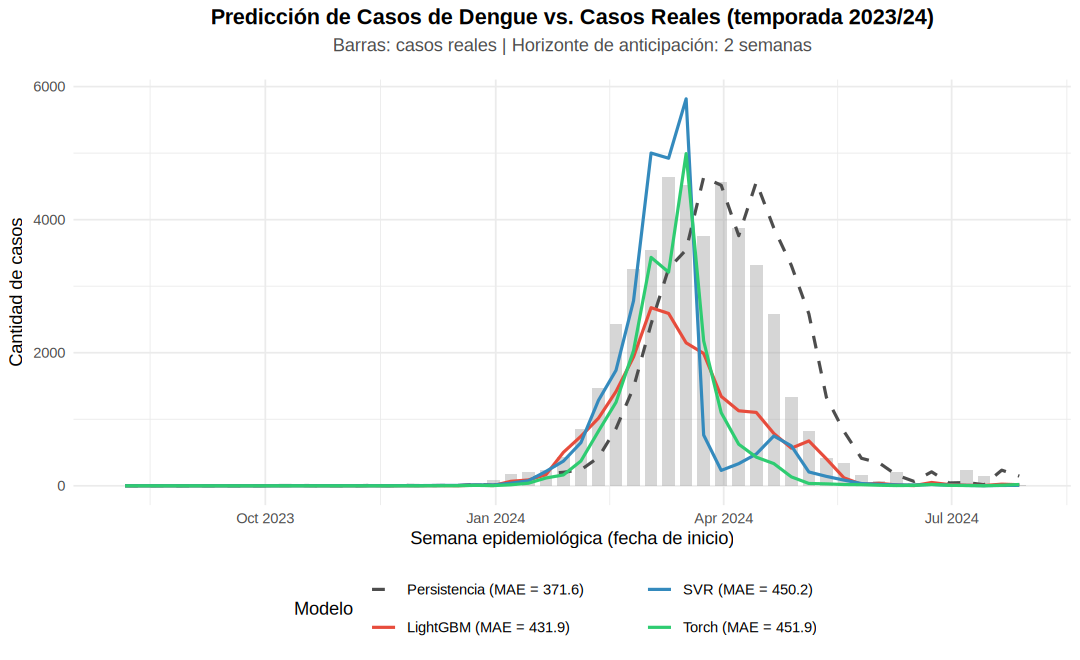

In [16]:
# 6.2 Casos reales vs. predichos en el Test Set
options(repr.plot.width = 9, repr.plot.height = 5.5)

df_pred <- data.table(Fecha = test_data$fecha_se, Real = y_test_real,
                      Persistencia = pred_naive, LightGBM = pred_lgb, SVR = pred_svm, Torch = pred_torch)
df_lineas <- data.table::melt(df_pred, id.vars = c("Fecha", "Real"),
                              variable.name = "Modelo", value.name = "Prediccion")
etiquetas <- setNames(paste0(names(mae_test), " (MAE = ", round(mae_test, 1), ")"), names(mae_test))

pred_plot <- ggplot(df_pred, aes(x = Fecha)) +
  geom_col(aes(y = Real), fill = "gray60", alpha = 0.4, width = 5) +
  geom_line(data = df_lineas, aes(y = Prediccion, color = Modelo, linetype = Modelo), linewidth = 0.9) +
  scale_color_manual(name = "Modelo", labels = etiquetas,
    values = c(Persistencia = "gray30", LightGBM = "#E74C3C", SVR = "#348ABD", Torch = "#2ECC71")) +
  scale_linetype_manual(name = "Modelo", labels = etiquetas,
    values = c(Persistencia = "dashed", LightGBM = "solid", SVR = "solid", Torch = "solid")) +
  theme_minimal() +
  labs(
    title = "Predicción de Casos de Dengue vs. Casos Reales (temporada 2023/24)",
    subtitle = "Barras: casos reales | Horizonte de anticipación: 2 semanas",
    x = "Semana epidemiológica (fecha de inicio)",
    y = "Cantidad de casos"
  ) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 13),
    plot.subtitle = element_text(color = "gray30", hjust = 0.5, margin = margin(b = 15)),
    legend.position = "bottom"
  ) +
  guides(color = guide_legend(nrow = 2), linetype = guide_legend(nrow = 2))

print(pred_plot)

## 7. Métricas de Error

Se evalúan los modelos sobre el *Test Set* con las siguientes métricas:
* **MAE:** error absoluto medio, en casos por semana.
* **RMSE:** penaliza más los errores grandes, que se concentran en el pico epidémico.
* **MedAE:** mediana del error absoluto; refleja el error en una semana típica.
* **MAE / media (%):** error relativo al nivel medio de casos (equivale al WAPE). Se clasifica como muy bueno (< 10%), bueno (10–20%), aceptable (20–50%) o pobre (> 50%).
* **RMSE / desvío (%):** por debajo de 100% el modelo es mejor que predecir siempre la media.
* **R²:** proporción de la variabilidad de los casos explicada por el modelo.
* **MAE Relativo:** MAE del modelo dividido por el MAE de la persistencia; por debajo de 1 el modelo supera a la línea base.

Además, el MAE se desagrega por semanas epidémicas.

In [17]:
# 7.1 Métricas de error absolutas y relativas
metricas <- function(y, p, y_naive) {
  e <- y - p; media <- mean(y); desv <- sd(y)
  mae <- mean(abs(e)); rmse <- sqrt(mean(e^2))
  data.table(MAE = mae, RMSE = rmse, MedAE = median(abs(e)),
             MAE_media_pct = 100 * mae / media,
             RMSE_desv_pct = 100 * rmse / desv,
             R2 = 1 - sum(e^2) / sum((y - media)^2),
             MASE = mae / mean(abs(y - y_naive)))
}
categoria <- function(pct) cut(pct, c(-Inf, 10, 20, 50, Inf),
  labels = c("Muy bueno (<10%)", "Bueno (10-20%)", "Aceptable (20-50%)", "Pobre (>50%)"))

tabla_metricas <- rbindlist(lapply(names(modelos), function(n)
  cbind(Modelo = n, metricas(y_test_real, modelos[[n]], pred_naive))))
tabla_metricas[, Categoria := categoria(MAE_media_pct)]

cat("Media del test:", round(mean(y_test_real), 1), "casos/semana | Desvío:", round(sd(y_test_real), 1), "\n\n")
print(tabla_metricas, digits = 3)

# MAE por fase: semanas epidémicas (> percentil 75 del test) vs. el resto
fase <- ifelse(y_test_real > quantile(y_test_real, 0.75), "Epidémica", "No epidémica")
tabla_fase <- rbindlist(lapply(names(modelos), function(n)
  data.table(Modelo = n, Fase = fase, AE = abs(y_test_real - modelos[[n]]))))[
  , .(MAE = round(mean(AE), 1), semanas = .N), by = .(Modelo, Fase)]
cat("\n")
print(tabla_fase)

Media del test: 846 casos/semana | Desvío: 1452.7 

         Modelo   MAE  RMSE MedAE MAE_media_pct RMSE_desv_pct    R2  MASE
         <char> <num> <num> <num>         <num>         <num> <num> <num>
1: Persistencia   372   675  69.5          43.9          46.5 0.780  1.00
2:     LightGBM   432   916  29.6          51.1          63.0 0.595  1.16
3:          SVR   450  1053  35.0          53.2          72.5 0.465  1.21
4:        Torch   452   950  47.3          53.4          65.4 0.564  1.22
            Categoria
               <fctr>
1: Aceptable (20-50%)
2:       Pobre (>50%)
3:       Pobre (>50%)
4:       Pobre (>50%)

         Modelo         Fase    MAE semanas
         <char>       <char>  <num>   <int>
1: Persistencia No epidémica  135.0      39
2: Persistencia    Epidémica 1081.3      13
3:     LightGBM No epidémica   44.7      39
4:     LightGBM    Epidémica 1593.6      13
5:          SVR No epidémica   64.5      39
6:          SVR    Epidémica 1607.3      13
7:        Torch No 

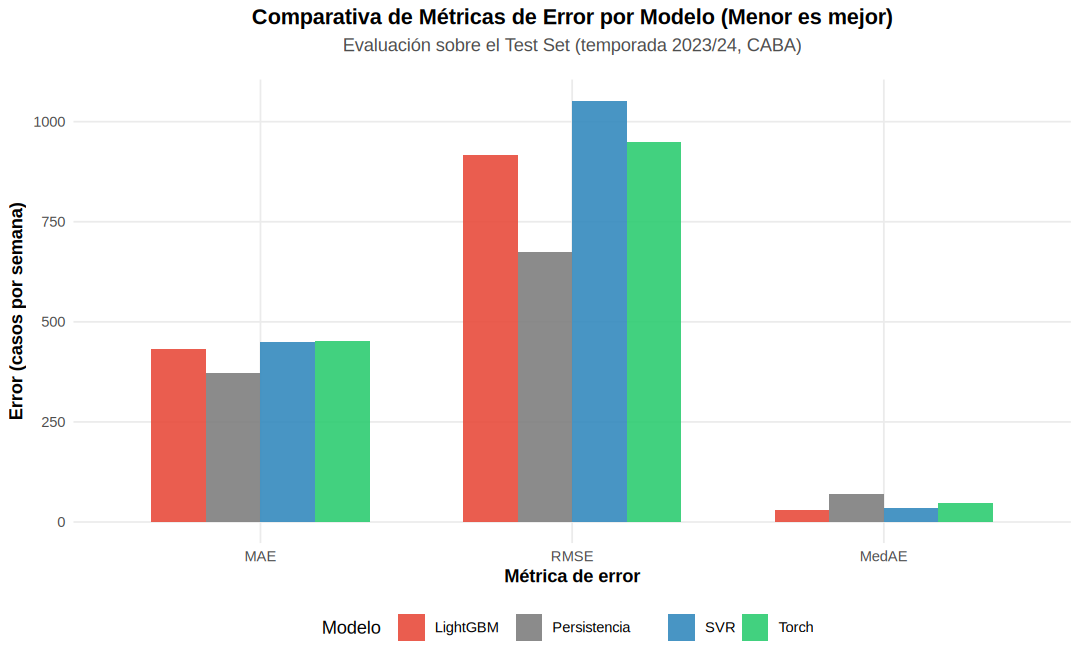

In [18]:
# 7.2 Gráfico comparativo de errores (MAE, RMSE, MedAE)
tabla_melted <- data.table::melt(tabla_metricas[, .(Modelo, MAE, RMSE, MedAE)], id.vars = "Modelo",
                                 variable.name = "Metrica", value.name = "Valor")

grafico_metricas <- ggplot(tabla_melted, aes(x = Metrica, y = Valor, fill = Modelo)) +
  geom_col(position = "dodge", width = 0.7, alpha = 0.9) +
  scale_fill_manual(values = c(Persistencia = "gray50", LightGBM = "#E74C3C", SVR = "#348ABD", Torch = "#2ECC71")) +
  theme_minimal() +
  labs(
    title = "Comparativa de Métricas de Error por Modelo (Menor es mejor)",
    subtitle = "Evaluación sobre el Test Set (temporada 2023/24, CABA)",
    x = "Métrica de error",
    y = "Error (casos por semana)",
    fill = "Modelo"
  ) +
  theme(
    plot.title = element_text(face = "bold", hjust = 0.5, size = 13),
    plot.subtitle = element_text(color = "gray30", hjust = 0.5, margin = margin(b = 15)),
    legend.position = "bottom",
    axis.title = element_text(face = "bold"),
    panel.grid.minor = element_blank()
  )

print(grafico_metricas)